# 04 Tuning and the training-vs-CV curve (M4)

**Owner:** Mahmoud · **Due:** CP3 (Wed 4 Nov) · **Covers:** proposal (random-search tuning), Lec 7 (loss vs metric, over/underfitting)

> **Draft.** Built on the features before the CP2 freeze. After Sumaiya freezes `clean.py` and `features.py`,
> I rerun the tuning commands below and then *Run All* here. Nothing in this notebook uses the test days.

## 1. Tuning commands (run in the terminal, not here)

Random search over each model's `SEARCH_SPACE`, scored by mean CV MAE on the 4 forward-chaining folds.
I tune on a sample because every try fits 4 models. RF gets fewer tries, as agreed in ALIGNMENT §6 (cut item 2).

```bash
python -m experiments.tune --model hgb --n-iter 20 --sample 150000
python -m experiments.tune --model rf  --n-iter 10 --sample 100000

# refit the best settings on all training rows (still CV, still no test days)
python -m experiments.run --model hgb --params-from results/tuning/hgb_base.json --name hgb_tuned_cv
python -m experiments.run --model rf  --params-from results/tuning/rf_base.json  --name rf_tuned_cv

# did tuning really help? paired bootstrap on the same orders
python -m experiments.run --model hgb
python -m experiments.compare results/runs/hgb_tuned_cv results/runs/hgb_base_cv
```

The HGB search includes `loss=absolute_error`. We report MAE, and absolute loss aims at the median instead of the
mean (Lec 7: train on the loss you are judged on).

In [1]:
import json, os, sys
from pathlib import Path

# run from notebooks/ or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import split
from common.config import RESULTS, SEED
from common.data import load_table
from common.features import FEATURE_SETS
from models import MODELS

FIG = ROOT / "figures" / "results"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    """Every report figure goes out as PDF + 300-dpi PNG, like figures/eda."""
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")

fs = FEATURE_SETS["base"]
train, _ = split.train_test(load_table())   # training days only; the test days are never touched here
print(f"training rows: {len(train):,}")

training rows: 406,553


## 2. What the search found

In [2]:
for model in ["hgb", "rf"]:
    path = RESULTS / "tuning" / f"{model}_base.csv"
    if not path.exists():
        print(f"{model}: not tuned yet, run the commands in section 1 first\n")
        continue
    table = pd.read_csv(path)
    print(f"{model}: {len(table)} tries, best CV MAE {table.cv_mean.min():.3f}, worst {table.cv_mean.max():.3f}")
    display(table.drop(columns="folds").head(5).round(3))
    if "loss" in table:
        print(table.groupby("loss").cv_mean.agg(["count", "min", "median"]).round(3))

hgb: 20 tries, best CV MAE 6.260, worst 6.325


,l2_regularization,learning_rate,loss,max_iter,max_leaf_nodes,min_samples_leaf,cv_mean,cv_std
0,7.853,0.038,absolute_error,800,76,70,6.260,0.182
1,0.268,0.042,squared_error,800,59,84,6.264,0.157
2,0.526,0.068,absolute_error,200,74,33,6.266,0.186
3,0.154,0.033,squared_error,400,104,63,6.268,0.156
4,0.001,0.063,squared_error,800,25,100,6.269,0.153


                count    min  median
loss                                
absolute_error      6  6.260   6.274
squared_error      14  6.264   6.287
rf: 10 tries, best CV MAE 6.370, worst 6.710


,max_depth,max_features,min_samples_leaf,n_estimators,cv_mean,cv_std
0,20.0,0.314,6,200,6.370,0.146
1,NaN,0.513,26,100,6.426,0.141
2,20.0,0.858,19,300,6.434,0.144
3,NaN,0.504,63,300,6.498,0.129
4,20.0,0.341,92,100,6.550,0.129


**Reading:** I tried 20 HGB settings on 150k rows. CV MAE only ranged from 6.263 to 6.327, so the settings matter
little. The best one uses `absolute_error` (learning rate 0.038, 76 leaves, 800 trees), and `absolute_error` also
had the better median (6.272 vs 6.287). On all training rows the tuned HGB gets **6.249** vs 6.278 for the defaults:
−0.03 min, bootstrap CI −0.034 to −0.025, so small but real. RF's best was 6.370 on the sample; on all rows the
tuned RF gets 6.317 vs 6.344. Tuned HGB still beats tuned RF by 0.068 min (CI −0.073 to −0.062).

One trade-off: absolute loss aims at the median, not the mean, so the share of orders more than 5 min later than
our ETA went up from 25.1% to 27.6%, and RMSE from 8.30 to 8.36. We report MAE, so I keep it, and the q80 model
(L4) is the one built for lateness. Both settings are frozen in `experiments/final_params/hgb.json` and `rf.json`.

## 3. Training vs CV error over model complexity (Lec 7)

One HGB setting changes at a time: `max_leaf_nodes`, the size of each tree. Everything else is fixed, and early
stopping is off so the number of trees doesn't change with it. For each fold, the training error is measured on
the days the model was fit on and the CV error on the next day. A 100k sample keeps it quick.

In [3]:
LEAVES = [2, 4, 8, 16, 31, 63, 127, 255, 511]
FIXED = dict(max_iter=300, learning_rate=0.1, min_samples_leaf=5, early_stopping=False)
sample = train.sample(100_000, random_state=SEED)

rows = []
for leaves in LEAVES:
    for fold, fit_rows, val_rows in split.forward_folds(sample):
        est = MODELS["hgb"].make(fs, SEED, max_leaf_nodes=leaves, **FIXED)
        est.fit(fit_rows[fs.columns], fit_rows["delivery_min"])
        for part, rows_ in [("training", fit_rows), ("CV", val_rows)]:
            err = (rows_["delivery_min"] - est.predict(rows_[fs.columns])).abs().mean()
            rows.append({"max_leaf_nodes": leaves, "fold": fold, "part": part, "mae": err})
curve = pd.DataFrame(rows).groupby(["max_leaf_nodes", "part"]).mae.agg(["mean", "std"]).unstack("part")
curve.round(3)

mean             std         
part               CV training     CV training
max_leaf_nodes                                
2               6.562    6.474  0.167    0.029
4               6.354    6.219  0.169    0.027
8               6.303    6.075  0.169    0.046
16              6.296    5.909  0.164    0.086
31              6.310    5.671  0.160    0.156
63              6.349    5.261  0.151    0.275
127             6.414    4.621  0.146    0.415
255             6.514    3.655  0.132    0.614
511             6.621    2.437  0.115    0.722

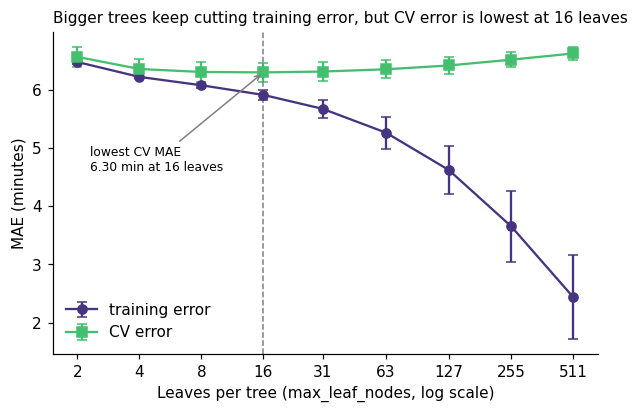

gap (CV - training): 0.39 min at 16 leaves, 4.18 min at 511 leaves


In [4]:
cv, tr = curve["mean"]["CV"], curve["mean"]["training"]
best = cv.idxmin()
gap_best, gap_max = cv[best] - tr[best], cv.iloc[-1] - tr.iloc[-1]

fig, ax = plt.subplots(figsize=(6.4, 3.8))
colors = plt.cm.viridis([0.15, 0.7])
for part, c, marker in [("training", colors[0], "o"), ("CV", colors[1], "s")]:
    ax.errorbar(curve.index, curve["mean"][part], yerr=curve["std"][part], marker=marker, color=c,
                capsize=3, label=f"{part} error")
ax.axvline(best, color="grey", ls="--", lw=1)
ax.annotate(f"lowest CV MAE\n{cv[best]:.2f} min at {best} leaves", (best, cv[best]),
            xytext=(2.3, 4.6), textcoords="data", fontsize=8,
            arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_xscale("log", base=2)
ax.set_xticks(LEAVES, [str(v) for v in LEAVES])
ax.set_xlabel("Leaves per tree (max_leaf_nodes, log scale)")
ax.set_ylabel("MAE (minutes)")
ax.set_title(f"Bigger trees keep cutting training error, but CV error is lowest at {best} leaves",
             fontsize=10, loc="left")
ax.legend(frameon=False)
save(fig, "hgb_complexity_curve")
plt.show()
print(f"gap (CV - training): {gap_best:.2f} min at {best} leaves, {gap_max:.2f} min at {LEAVES[-1]} leaves")

**Reading:** with 2 leaves both errors are high (6.47 training, 6.56 CV), so the model is too simple
(underfitting). CV error is lowest at 16 leaves (6.30). After that, training error keeps falling to 2.45 at 511
leaves, but CV error climbs back to 6.63: the trees start memorising the fit days (overfitting). The gap between
them grows from 0.38 to 4.18 min. **Why the curve says 16 leaves but the frozen model uses 76:** the curve changes only the number of leaves and
keeps everything else fixed (300 trees, learning rate 0.1, leaves as small as 5 orders), so it isolates one knob.
The tuning search changed all the settings together. The frozen model pairs 76 leaves with a smaller learning
rate (0.038), bigger leaves (at least 70 orders) and strong L2 (7.9), and those three hold back the overfitting
that this curve shows. So 16 is the best number of leaves *for these fixed settings*, not for the tuned ones.

**Informs:** the range of `max_leaf_nodes` in `SEARCH_SPACE` (15 to 127) and the Methodology figure.